# Check: Isaac Sim, the samples and a first picture on this machine

Run this notebook first on a new machine. It answers three questions. On the development server it takes 14 seconds
with a CUDA device and 17 seconds with Warp's CPU device.

1. Does Isaac Sim start inside this Jupyter kernel, and can its RTX renderer draw here?
2. Are the eight sample volumes there, and what are their voxel sizes?
3. Does a picture of a USD stage come out, with the true voxel size and with the voxel size ignored?

**Kernel.** Select the kernel `ncntm-isaacsim`. It is the Python of Isaac Sim and is registered once per machine with
`python scripts/install_kernel.py` (add `--accept-eula` after reading the NVIDIA Omniverse licence, and `--gpu N` on a
machine with several GPUs). The same checks run without Jupyter as `python scripts/selftest.py`.

**What has been tested.** This notebook was executed on the development server: x86-64, Isaac Sim 6.2.0, GPUs that
cannot create a graphics context. Isaac Sim starts there without its renderer, and every picture below was drawn by
the ray caster of this package, which runs on NVIDIA Warp (CUDA or CPU). On a DGX Spark nothing of this has run yet.
Where RTX works, the first picture gets a second panel drawn by RTX; nobody has seen that panel so far. There, expect
the first start of Isaac Sim to take minutes, because its renderer compiles shaders once (not measured).

**Order.** The next cell must run before anything imports `pxr` (OpenUSD) or `warp`: Isaac Sim brings its own OpenUSD
and cannot start once another one is loaded. `kit.start_kit` enforces this: if the order is wrong it refuses and names
the module that came too early.

In [1]:
import sys
from pathlib import Path

# the repository is the folder that holds ncntm/viz: walk up from the folder of this notebook
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ncntm" / "viz").is_dir()), None)
assert REPO is not None, "open this notebook from inside the ncntm repository (no folder ncntm/viz above it)"
sys.path.insert(0, str(REPO))

from ncntm.viz import kit            # loads neither OpenUSD nor Warp nor Isaac Sim
session = kit.start_kit()            # starts Isaac Sim if it is installed; run again: the same session

## 1. What runs here

`session.describe()` says what was started and why. One of three situations applies:

| The first line and the `RTX renderer` line say | Situation | The stage is held by | Pictures are drawn by |
|---|---|---|---|
| `Isaac Sim: not running (tier 'off')` | No Isaac Sim in this interpreter | plain OpenUSD | the Warp ray caster |
| `tier 'usd'`, `RTX renderer: not available ...` | Isaac Sim without a renderer, as on the development server | Isaac Sim | the Warp ray caster |
| `tier 'full'`, `RTX renderer: available ...` | Isaac Sim with RTX, as expected on a DGX Spark | Isaac Sim | RTX, with the Warp picture beside it |

The notebooks run in all three. In the first two, the reason why RTX cannot draw is part of the text below.

In [2]:
def tidy(text):
    "Folders of this machine shortened, so that a saved notebook does not name a home directory."
    return str(text).replace(str(REPO), "<repository>").replace(str(Path.home()), "~")


print(tidy(session.describe()))

if session.app is None:
    situation = "1: no Isaac Sim, plain OpenUSD, pictures by the Warp ray caster"
elif not session.renderer_available:
    situation = "2: Isaac Sim holds the stage, pictures by the Warp ray caster"
else:
    situation = "3: Isaac Sim holds the stage, pictures by RTX"
print("\nSituation", situation)

Isaac Sim: Kit 110.4.0, tier 'usd', 24 extensions, started in 0.53 s
  tier chosen automatically: no usable graphics device was found (see the RTX line); NCNTM_KIT or start_kit(tier=...) overrides the choice
  OpenUSD 25.11 (Kit build)   Warp 1.19.0
  GPU: CUDA_VISIBLE_DEVICES = 6: GPU 6 is cuda:0 in this process
  RTX renderer: not available on this machine because tier 'usd' loads no renderer; the graphics probe says: 8 NVIDIA EGL devices found, but eglInitialize failed on all of them (EGL_BAD_ACCESS): the driver cannot create a graphics context on this machine. To try RTX all the same: start_kit(tier='full') in a new kernel, or NCNTM_KIT=full
  crash reporter and telemetry: off
  Kit files: ~/.cache/ncntm/kit   log: ~/.cache/ncntm/kit/logs/Kit/ncntm-kit-usd/0.2/kit_20261124_201207.log   errors in the log: 0

Situation 2: Isaac Sim holds the stage, pictures by the Warp ray caster


## 2. The samples

Eight small crops of public electron-microscopy volumes are in `samples/`, each with the image and, for six of them,
an instance segmentation (voxel label = instance id). Every line below is `VoxelGrid.describe()` of one file: the
number of voxels, the size of one voxel in nanometres, the size of the whole block, and the anisotropy, which is the
section thickness divided by the pixel size.

What to look for: `snemi3d` has voxels of 6 x 6 x 30 nm (5:1), `cremi_a` of 4 x 4 x 40 nm (10:1), `fib25` of
8 x 8 x 8 nm (1:1). The three blocks are all about 3 um on every side, although their arrays have very different shapes.

In [3]:
from ncntm.viz import samples

lines = [samples.load_sample(name).describe() for name in samples.list_samples()]      # reads every file
print("samples in", tidy(samples.samples_dir()))
print("\n".join(lines))

samples in <repository>/samples
snemi3d: 512 x 512 x 100 voxels (x, y, z) of 6 x 6 x 30 nm = 3.07 x 3.07 x 3.00 um, anisotropy 5:1, 138 instances
cremi_a: 768 x 768 x 75 voxels (x, y, z) of 4 x 4 x 40 nm = 3.07 x 3.07 x 3.00 um, anisotropy 10:1, 9017 instances
fib25: 384 x 384 x 384 voxels (x, y, z) of 8 x 8 x 8 nm = 3.07 x 3.07 x 3.07 um, anisotropy 1:1, 768 instances
flywire: 384 x 384 x 75 voxels (x, y, z) of 8 x 8 x 40 nm = 3.07 x 3.07 x 3.00 um, anisotropy 5:1, 620 instances
microns: 384 x 384 x 75 voxels (x, y, z) of 8 x 8 x 40 nm = 3.07 x 3.07 x 3.00 um, anisotropy 5:1, 278 instances
h01: 384 x 384 x 47 voxels (x, y, z) of 4 x 4 x 33 nm = 1.54 x 1.54 x 1.55 um, anisotropy 8.25:1, 68 instances
mitoem2_podo: 192 x 192 x 192 voxels (x, y, z) of 16 x 16 x 16 nm = 3.07 x 3.07 x 3.07 um, anisotropy 1:1, image only
cosem_hela3: 192 x 192 x 192 voxels (x, y, z) of 4 x 4 x 4 nm = 0.77 x 0.77 x 0.77 um, anisotropy 1:1, image only


## 3. A small stage

Everything this package draws is first written into one OpenUSD stage. The cell below builds it for `snemi3d`:

* three slices of the volume: **rawvalue** (the stored numbers as greys), **voxvalue** (the same numbers normalised to
  [0, 1], shown in a colour map) and **instance** (one colour per instance id);
* one neurite of the segmentation in three more forms: its surface (layer **instance**), its **skeleton** and a mixture of 32 **gaussian**s;
* a **frame**: the box of the block, three axes and a bar, each 500 nm of tissue long.

The printed tree shows where the voxel size lives. Geometry under `voxels` is written in voxel index units, and the
one attribute `voxels.xformOp:scale` turns indices into nanometres. The stage holds two values for it: (6, 6, 30) in
the variant `physical` and (6, 6, 6) in the variant `index`, which is what a program assumes that ignores the voxel size.

In [4]:
import warp
warp.config.log_level = warp.LOG_WARNING                     # keep Warp's start-up report out of the output

from ncntm.viz import convert, stage as S                    # stage imports pxr: only after start_kit

sample = samples.load_sample("snemi3d")
grid = sample.grid
subject = sample.skeleton_subjects[0]                        # a neurite that runs across the sections
mask = sample.mask(subject)                                  # its voxels: a boolean (z, y, x) array
nz, ny, nx = grid.shape_zyx

OUT = REPO / "build" / "check_ISAACSIM"                      # build/ is ignored by git
dataset = S.Dataset.from_sample(S.new_stage(OUT / "snemi3d.usdc"), sample)
dataset.add_slices("rawvalue", z=0)                          # the floor of the block
dataset.add_slices("voxvalue", y=ny - 1)                     # the far wall on the right
dataset.add_slices("instance", x=0)                          # the far wall on the left
dataset.add_surface(convert.instance_to_mesh(mask, grid, instance_id=subject), opacity=0.35)
dataset.add_skeleton(convert.instance_to_skeleton(mask, grid, instance_id=subject))
dataset.add_gaussians(convert.instance_to_gaussians(mask, grid, k=32, instance_id=subject))
dataset.add_frame()
dataset.author_camera()

print(f"instance {subject}: {int(mask.sum()):,} voxels\n")
print(dataset.describe())

instance 10: 818,858 voxels

/World/snemi3d   512 x 512 x 100 voxels (x, y, z) of 6 x 6 x 30 nm = 3.07 x 3.07 x 3.00 um, anisotropy 5:1
  space = 'physical'   (variants: physical, index)
  voxels.xformOp:scale   physical (6, 6, 30) nm   index (6, 6, 6) nm   <- the anisotropy
  1 stage unit = 1000 nm; metersPerUnit = 1 (magnified model)
    voxels                   Xform  frame: voxel index (i, j, k)
      rawvalue               Xform  [layer rawvalue]
        slice_z0000          Mesh  slice
      voxvalue               Xform  [layer voxvalue]
        slice_y0511          Mesh  slice
      instance               Xform  [layer instance]
        slice_x0000          Mesh  slice
        surface_10           Mesh  surface
    physical                 Xform  frame: nanometres (x, y, z)
      skeleton               Xform  [layer skeleton]
        tubes_10             BasisCurves  tubes
        nodes_10             PointInstancer  nodes
      gaussian               Xform  [layer gaussian]
   

## 4. The first picture

The stage is saved, handed to Isaac Sim, and drawn. Saving comes first for a reason: RTX reads the pictures of the
slices from PNG files that lie next to the stage file. `session.open_stage` gives the stage to Isaac Sim; without
Isaac Sim it opens the file with plain OpenUSD, so the same lines run everywhere.

`view.compare_backends` draws the stage with the Warp ray caster and, where RTX works, with RTX through the same
camera. Where RTX does not work, the caption says why.

What to look at in the Warp picture: the block is a cube, because 512 voxels of 6 nm and 100 sections of 30 nm are both
about 3 um. Floor: one section in grey (rawvalue). Right wall: a cut across the sections in the colour map (voxvalue);
its horizontal stripes are the 30 nm sections. Left wall: instance labels, with stair steps of one section each. In
front of the walls: the neurite as a see-through surface, its skeleton (black tubes, red spheres at branch points, blue
at end points) and its Gaussians (soft blobs). The red sphere at the top reaches out of the block: its node lies at the
border of the crop and is drawn with its full radius.

The black bar in front and the coloured axes at the left corner stand for 500 nm of tissue each: x red, z blue. The
green y axis lies in the edge between the floor and the left wall and shows only as a thin line.

stage file: build/check_ISAACSIM/snemi3d.usdc (3.3 MB)


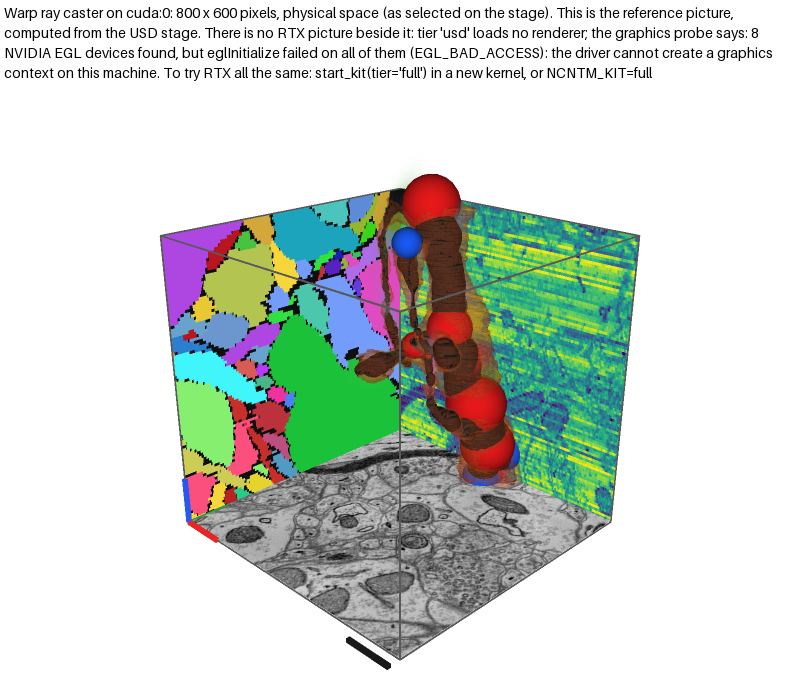

drawn by: Warp only


In [5]:
from ncntm.viz import figure, view

saved = dataset.save()                                       # the stage file; its textures are in textures/ beside it
stage = session.open_stage(saved)                            # Isaac Sim holds the stage now (or plain OpenUSD does)
print("stage file:", Path(saved).relative_to(REPO), f"({Path(saved).stat().st_size / 1e6:.1f} MB)")

figure.show(view.compare_backends(stage, size=(800, 600)))
print("drawn by:", "RTX and Warp" if view.last_backend() == "rtx" else "Warp only")

## 5. The same stage with the voxel size ignored

`space="index"` draws every voxel as a cube of 6 nm, which is what a viewer shows that reads the array and does not
read the voxel size. Nothing else changes: same stage, same camera. The selection on the stage itself is not touched;
`view.render` switches the space for one picture only.

What to look at: (b) is 5 times too flat. The block is 0.6 um high instead of 3 um, the neurite is squashed, its round
skeleton spheres are discs, and the blue z axis, which stands for 500 nm of tissue like the red x axis, is drawn one
fifth as long. Lengths measured in (b) along z are wrong by a factor of 5; lengths in the section plane are right.

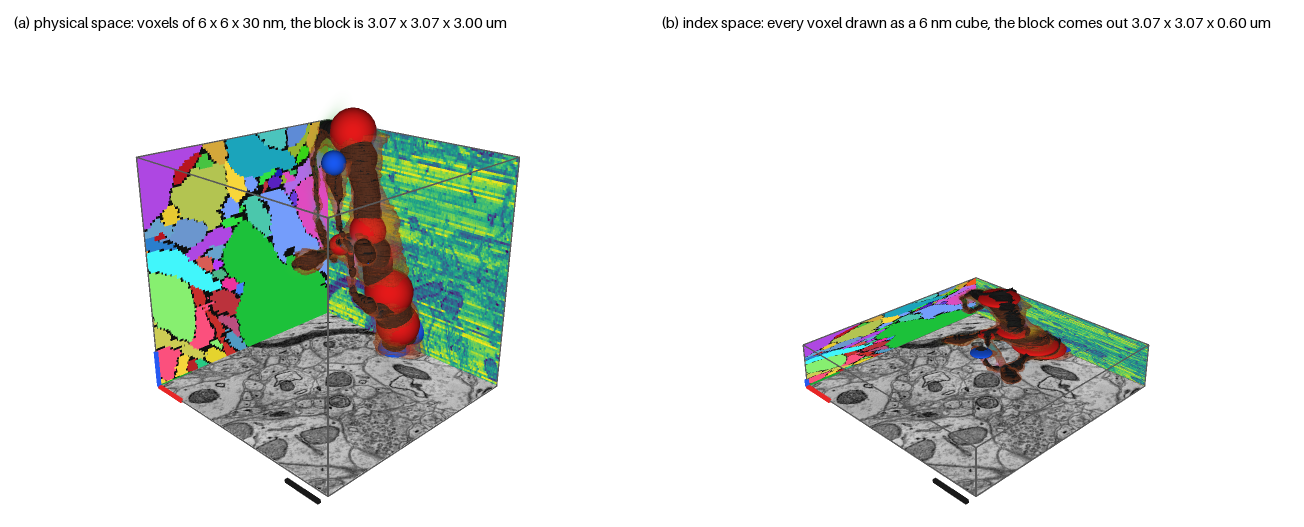

drawn by: warp
space selected on the stage: physical
texture files RTX would not find: 0
errors in the log of Isaac Sim: 0


In [6]:
physical = view.render(stage, size=(640, 480), space="physical")
index = view.render(stage, size=(640, 480), space="index")

extent = grid.extent_xyz_nm / 1000.0                         # (x, y, z) in micrometres
flat = grid.extent_nm("index") / 1000.0
figure.show(figure.side_by_side(physical, index, labels=True, size=15, captions=[
    f"physical space: voxels of 6 x 6 x 30 nm, the block is {extent[0]:.2f} x {extent[1]:.2f} x {extent[2]:.2f} um",
    f"index space: every voxel drawn as a 6 nm cube, the block comes out {flat[0]:.2f} x {flat[1]:.2f} x {flat[2]:.2f} um"]))

print("drawn by:", view.last_backend())
print("space selected on the stage:", S.find_datasets(stage)[0].space)
print("texture files RTX would not find:", len(view.missing_textures(stage)))
print("errors in the log of Isaac Sim:", len(session.kit_errors()))

## Stopping

The stage file stays in `build/check_ISAACSIM/`. Nothing else is saved when the kernel stops.

Isaac Sim lives inside this kernel. To stop it, **restart or shut down the kernel**. Never call `session.app.close()`
(or `simulation_app.close()`): inside Jupyter that call waits for the kernel's own event loop and does not return, so
`kit.py` replaces it by a function that only prints this advice. Another tier, for example `kit.start_kit(tier="full")`
to try RTX, also needs a restarted kernel: a process can start Isaac Sim once.